In [70]:
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("future.no_silent_downcasting", True)
warnings.filterwarnings('ignore')
plt.style.use("dark_background")

## Import and Prepare Data

**Select either  `removal` or `recovery` as the desired Output here!**

After selecting the desired output size, the required data is imported. For simplicity's sake, the features (Flow_C, Flow_P, and Current_Limit_P) are always imported from the cache folder here, which saves having to convert them to the correct format from the CSV files. Depending on which output variable you selected previously, either the data for the output variable *Average CO2 Removal* or *Average Water Recovery* is loaded.

In [71]:
output = "removal"

In [72]:
cached_objects_prepared_data_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "cached_objects", "prepared_data"
)

X = joblib.load(os.path.join(cached_objects_prepared_data_path, "X.npy"))

if output == "removal":
    y = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_removal.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_label_removal.npy")
    )
    y_name = "removal"
elif output == "recovery":
    y = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_recovery.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_label_recovery.npy")
    )
    y_name = "recovery"

## Random Forest Regression Model

In addition to the quadratic model with linear regression, which can map quadratic properties well, we will now consider another approach to modeling using *Random Forest*. The *Random Forest* approach offers the following advantages over the linear regression approach:

- Nonlinear behavior and dependencies on inputs could be better represented.
- Potentially less overfitting, as results are averaged across several decision trees.
- In the future, Random Forest could also be used to map complex interactions between two input variables.

The following settings are used here when creating the Random Forest:

The following settings are used here when creating the Random Forest:

- The number of decision trees is specified via *n_estimators*; too many decision trees
- The maximum depth of the individual decision trees is controlled via *max_depth*; this must not be too high under any circumstances, as otherwise there is a risk of overfitting
- *min_samples_split* specifies after how many data points a node is further divided; here too, the number must not be too high, otherwise the trees will be too strongly adapted to the training data
- *min_samples_leaf* specifies how many data points must remain in a leaf after a node is split. Here, there is a higher risk of overfitting with smaller values, as the trees are then more specialized
- The number of features relevant for a split is given by *max_features*. More diverse trees can be achieved here by using a smaller value, as not every tree sees the same data at every split
- The data that the individual trees receive during the decision-making process can either be drawn randomly by setting *bootstrap* to true, or it can always correspond to the entire data set. Greater diversity can be achieved by not always having the trees operate on exactly the same data.

In [73]:
# Create and fit Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    random_state=42,
)
rf_model.fit(X, y[:, 0])

# Get Predictions
y_pred = rf_model.predict(X)

## Random Forest Key Metrics

In order to better evaluate and compare the model that was created here, we will now discuss a few key metrics.

Feature importance indicates which feature contributed most to improvements in the model. If it is high for a feature, as is the case here for Flow_C, then Flow_C has contributed more to improvements in the decision trees than the feature Current_Limit_P. This can be concluded primarily from the fact that the variance in the underlying data set for Current_Limit_P is very low.

In the case of residual distribution, the distribution is ideally symmetrical around 0, which is not the case for average water recovery, as can be seen below. This means that the model can still be used, but the results should be critically questioned. However, the distribution around 0 for the output average CO2 removal is significantly better.

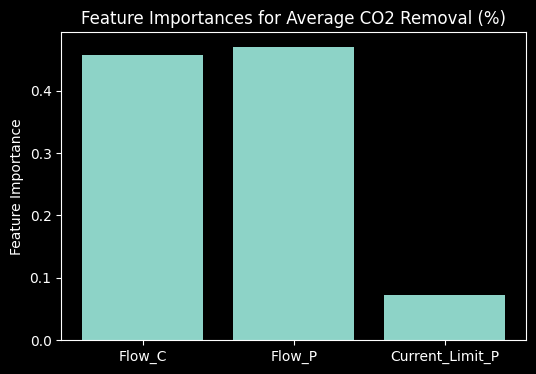

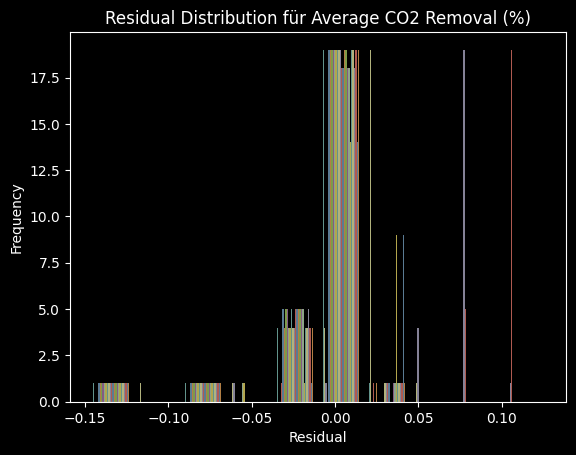

In [74]:
importances = rf_model.feature_importances_
features = ["Flow_C", "Flow_P", "Current_Limit_P"]

# Visualize Feature Importances
plt.figure(figsize=(6, 4))
plt.bar(features, importances)
plt.ylabel("Feature Importance")
plt.title(f"Feature Importances for {y_label}")
plt.show()

# Visualize Residual Distribution
residuals = y - y_pred
plt.hist(residuals, bins=10, alpha=0.7)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title(f"Residual Distribution für {y_label}")
plt.show()

## Validation via LOOCV

Here, too, *Leave-One-Out Cross-Validation* is used to minimize the amount of data sacrificed as test data. The mean squared error is very low for both average CO2 removal and average water recovery.

In [75]:
loo = LeaveOneOut()
y_true = []
y_pred = []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx, 0], y[test_idx, 0]

    # Train Random Forest on train split (1 sample)
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        bootstrap=True,
        random_state=42,
    )
    model.fit(X_train, y_train)

    y_pred.append(model.predict(X_test)[0])
    y_true.append(y_test[0])

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate LOOCV MSE
mse = mean_squared_error(y_true, y_pred)
print(f"Random Forest LOOCV MSE for {y_label}: {mse:.5f}")

Random Forest LOOCV MSE for Average CO2 Removal (%): 0.00049


## Export Model

Now all relevant model parameters are exported so that they can be reused in further steps, such as optimization.

In [76]:
cached_objects_model_rf_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "cached_objects", "model_random_forest", y_name
)

joblib.dump(model, os.path.join(cached_objects_model_rf_path, "rf_model.pkl"))
joblib.dump(y_pred, os.path.join(cached_objects_model_rf_path, "y_pred.npy"))

['c:\\Users\\david\\HKA-lokal\\5. Semester\\Projektarbeit\\Optimierung\\CapBioCO2_Optimization\\notebooks\\..\\cached_objects\\model_random_forest\\removal\\y_pred.npy']